In [1]:
import io
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models
import kornia.augmentation as K
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

torch.set_num_threads(4)
torch.manual_seed(42)
np.random.seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
classes = ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']
data_dir = '../../data/raw/fer2013/'
os.makedirs('weights', exist_ok=True)
os.makedirs('../../results/emotion', exist_ok=True)

print('Dataset 1: FER2013 - https://huggingface.co/datasets/Aaryan333/fer2013_train_publicTest_privateTest')
print('Dataset 2: AffectNet subset - https://huggingface.co/datasets/Mauregato/affectnet_short')
print('Device:', torch.cuda.get_device_name(0) if device == 'cuda' else 'cpu')

Dataset 1: FER2013 - https://huggingface.co/datasets/Aaryan333/fer2013_train_publicTest_privateTest
Dataset 2: AffectNet subset - https://huggingface.co/datasets/Mauregato/affectnet_short
Device: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
print('Loading FER2013: train, validation (publicTest) and test (privateTest)')
def load(split):
    df = pd.read_parquet(data_dir + split + '.parquet')
    images = np.stack([np.array(Image.open(io.BytesIO(img['bytes'])).convert('L')) for img in df['image']])
    return torch.tensor(images).unsqueeze(1).float() / 255, torch.tensor(df['label'].values)

X_train, y_train = load('train')
X_val, y_val = load('publicTest')
X_test, y_test = load('privateTest')
print('Train:', len(X_train), '| Validation:', len(X_val), '| Test:', len(X_test), '| Image size:', tuple(X_train.shape[1:]))
print(pd.Series(y_train.numpy()).map(dict(enumerate(classes))).value_counts())

Loading FER2013: train, validation (publicTest) and test (privateTest)


Train: 28709 | Validation: 3589 | Test: 3589 | Image size: (1, 48, 48)
happy       7215
neutral     4965
sad         4830
fear        4097
angry       3995
surprise    3171
disgust      436
Name: count, dtype: int64


In [3]:
print('Loading AffectNet: find the face with YuNet, square crop like the live app, 48x48 grayscale, contempt dropped')
detector = cv2.FaceDetectorYN.create('../face_recognition/models/face_detection_yunet_2023mar.onnx', '', (288, 288), score_threshold=0.7)
affectnet_to_fer = {0: 0, 1: 5, 3: 3, 4: 6, 5: 2, 6: 4, 7: 1}

def load_affectnet(split):
    df = pd.read_parquet('../../data/raw/affectnet/' + split + '.parquet')
    images, labels = [], []
    for img, label in zip(df['image'], df['label']):
        if label not in affectnet_to_fer:
            continue
        frame = cv2.resize(cv2.cvtColor(np.array(Image.open(io.BytesIO(img['bytes'])).convert('RGB')), cv2.COLOR_RGB2BGR), (192, 192))
        frame = cv2.copyMakeBorder(frame, 48, 48, 48, 48, cv2.BORDER_REPLICATE)
        _, faces = detector.detect(frame)
        if faces is None:
            continue
        x, y, w, h = faces[0][:4]
        cx, cy, half = x + w / 2, y + h / 2, h / 2
        face = frame[max(int(cy - half), 0):int(cy + half), max(int(cx - half), 0):int(cx + half)]
        images.append(cv2.resize(cv2.cvtColor(face, cv2.COLOR_BGR2GRAY), (48, 48)))
        labels.append(affectnet_to_fer[label])
    return torch.tensor(np.stack(images)).unsqueeze(1).float() / 255, torch.tensor(labels)

X_aff, y_aff = load_affectnet('train')
X_aff_test, y_aff_test = load_affectnet('val')
order = torch.randperm(len(X_aff))
n_val = len(X_aff) // 10
X_aff_val, y_aff_val = X_aff[order[:n_val]], y_aff[order[:n_val]]
X_aff_train, y_aff_train = X_aff[order[n_val:]], y_aff[order[n_val:]]
print('Train:', len(X_aff_train), '| Validation:', len(X_aff_val), '| Test (AffectNet val split):', len(X_aff_test))
print(pd.Series(y_aff_train.numpy()).map(dict(enumerate(classes))).value_counts())

Loading AffectNet: find the face with YuNet, square crop like the live app, 48x48 grayscale, contempt dropped


Train: 18825 | Validation: 2091 | Test (AffectNet val split): 5230
neutral     3697
happy       3652
surprise    2921
fear        2286
angry       2280
sad         2238
disgust     1751
Name: count, dtype: int64


One training image per emotion: FER2013 (top) and AffectNet after cropping (bottom)


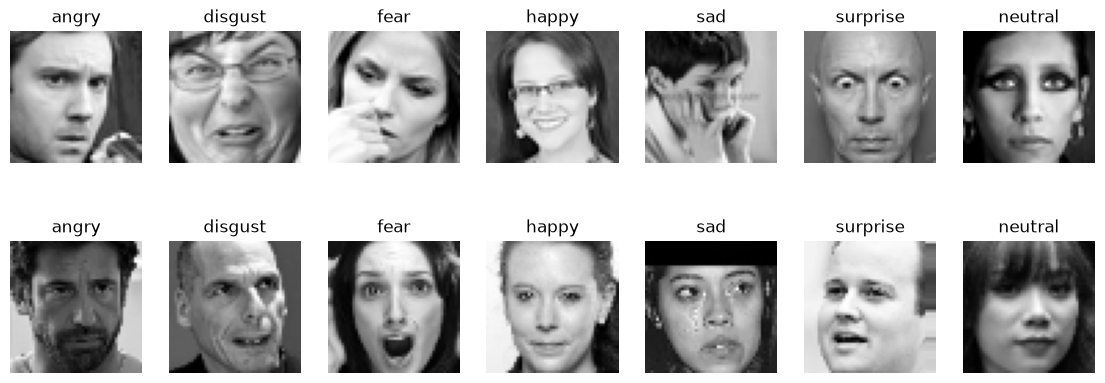

In [4]:
print('One training image per emotion: FER2013 (top) and AffectNet after cropping (bottom)')
plt.figure(figsize=(14, 5))
for i, name in enumerate(classes):
    for row, (X, y) in enumerate([(X_train, y_train), (X_aff_train, y_aff_train)]):
        plt.subplot(2, 7, row * 7 + i + 1)
        plt.imshow(X[y == i][0, 0], cmap='gray')
        plt.title(name)
        plt.axis('off')
plt.savefig('../../results/emotion/samples.png', bbox_inches='tight')
plt.show()

In [5]:
print('Model 1: small CNN trained from scratch')
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                                 nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                                 nn.MaxPool2d(2), nn.Dropout(0.25))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128), block(128, 256))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(256 * 3 * 3, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 7))

    def forward(self, x):
        return self.classifier(self.features(x))

print('Model 2: ResNet-18 from ImageNet, conv1 + layer1 frozen, the rest fine-tuned')
class ResNetEmotion(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = models.resnet18(weights='IMAGENET1K_V1')
        self.net.fc = nn.Linear(512, 7)
        for layer in [self.net.conv1, self.net.bn1, self.net.layer1]:
            layer.requires_grad_(False)
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = F.interpolate(x, size=96, mode='bilinear').repeat(1, 3, 1, 1)
        return self.net((x - self.mean) / self.std)

for name, model in [('Small CNN', SmallCNN()), ('ResNet-18', ResNetEmotion())]:
    print(f'  {name}: {sum(p.numel() for p in model.parameters() if p.requires_grad):,} trainable parameters')

Model 1: small CNN trained from scratch
Model 2: ResNet-18 from ImageNet, conv1 + layer1 frozen, the rest fine-tuned
  Small CNN: 1,765,479 trainable parameters
  ResNet-18: 11,022,599 trainable parameters


In [6]:
print('Training setup: flip + small rotate/shift/zoom on the GPU, cross-entropy, Adam, cosine learning rate')
augment = nn.Sequential(K.RandomHorizontalFlip(), K.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)))
loss_fn = nn.CrossEntropyLoss()

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(X[i:i + 512].to(device)).softmax(1).cpu() for i in range(0, len(X), 512)])

def train(model, epochs, lr, path, X_train, y_train, X_val, y_val):
    model = model.to(device)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs)
    history, best = [], 0
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X_train))
        total = 0
        for i in range(0, len(X_train), 128):
            idx = order[i:i + 128]
            x = augment(X_train[idx].to(device))
            loss = loss_fn(model(x), y_train[idx].to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(idx)
        scheduler.step()
        val_acc = accuracy_score(y_val, predict(model, X_val).argmax(1))
        history.append((total / len(X_train), val_acc))
        if val_acc > best:
            best = val_acc
            torch.save(model.state_dict(), path)
        print(f'Epoch {epoch + 1}/{epochs}  loss {total / len(X_train):.3f}  validation accuracy {val_acc:.4f}')
    model.load_state_dict(torch.load(path))
    print('Best validation accuracy:', round(best, 4))
    return model, history

Training setup: flip + small rotate/shift/zoom on the GPU, cross-entropy, Adam, cosine learning rate


In [7]:
print('Training the small CNN (40 epochs)')
cnn, cnn_history = train(SmallCNN(), 40, 1e-3, 'weights/emotion_cnn.pt', X_train, y_train, X_val, y_val)

Training the small CNN (40 epochs)


Epoch 1/40  loss 1.828  validation accuracy 0.2566


Epoch 2/40  loss 1.712  validation accuracy 0.3689


Epoch 3/40  loss 1.523  validation accuracy 0.4603


Epoch 4/40  loss 1.429  validation accuracy 0.4809


Epoch 5/40  loss 1.365  validation accuracy 0.5035


... (31 outputs left out)

Epoch 37/40  loss 0.976  validation accuracy 0.6464


Epoch 38/40  loss 0.983  validation accuracy 0.6431


Epoch 39/40  loss 0.978  validation accuracy 0.6431


Epoch 40/40  loss 0.980  validation accuracy 0.6417
Best validation accuracy: 0.6464


In [8]:
print('Fine-tuning ResNet-18 on FER2013 (20 epochs)')
resnet, resnet_history = train(ResNetEmotion(), 20, 3e-4, 'weights/emotion_resnet18.pt', X_train, y_train, X_val, y_val)

Fine-tuning ResNet-18 on FER2013 (20 epochs)


Epoch 1/20  loss 1.248  validation accuracy 0.6024


Epoch 2/20  loss 0.994  validation accuracy 0.6264


Epoch 3/20  loss 0.898  validation accuracy 0.6353


Epoch 4/20  loss 0.821  validation accuracy 0.6473


Epoch 5/20  loss 0.755  validation accuracy 0.6417


... (11 outputs left out)

Epoch 17/20  loss 0.170  validation accuracy 0.6890


Epoch 18/20  loss 0.152  validation accuracy 0.6918


Epoch 19/20  loss 0.146  validation accuracy 0.6932


Epoch 20/20  loss 0.142  validation accuracy 0.6882
Best validation accuracy: 0.6949


In [9]:
print('Fine-tuning ResNet-18 on FER2013 + AffectNet (20 epochs)')
combined, combined_history = train(ResNetEmotion(), 20, 3e-4, 'weights/emotion_resnet18_combined.pt',
                                   torch.cat([X_train, X_aff_train]), torch.cat([y_train, y_aff_train]),
                                   torch.cat([X_val, X_aff_val]), torch.cat([y_val, y_aff_val]))

Fine-tuning ResNet-18 on FER2013 + AffectNet (20 epochs)


Epoch 1/20  loss 1.258  validation accuracy 0.6070


Epoch 2/20  loss 1.031  validation accuracy 0.6106


Epoch 3/20  loss 0.953  validation accuracy 0.6315


Epoch 4/20  loss 0.891  validation accuracy 0.6363


Epoch 5/20  loss 0.837  validation accuracy 0.6415


... (11 outputs left out)

Epoch 17/20  loss 0.270  validation accuracy 0.6805


Epoch 18/20  loss 0.255  validation accuracy 0.6782


Epoch 19/20  loss 0.247  validation accuracy 0.6768


Epoch 20/20  loss 0.242  validation accuracy 0.6798
Best validation accuracy: 0.6805


Training curves


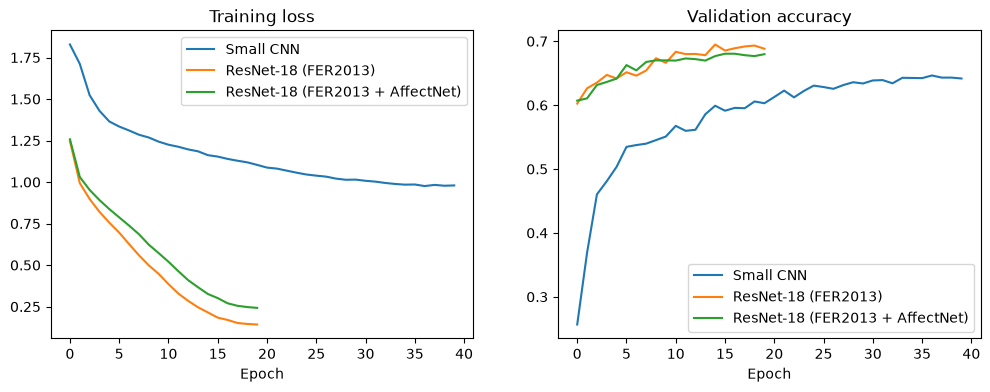

In [10]:
print('Training curves')
plt.figure(figsize=(12, 4))
for i, title in enumerate(['Training loss', 'Validation accuracy']):
    plt.subplot(1, 2, i + 1)
    plt.plot([h[i] for h in cnn_history], label='Small CNN')
    plt.plot([h[i] for h in resnet_history], label='ResNet-18 (FER2013)')
    plt.plot([h[i] for h in combined_history], label='ResNet-18 (FER2013 + AffectNet)')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.legend()
plt.savefig('../../results/emotion/training_curves.png', bbox_inches='tight')
plt.show()

In [11]:
print('Test results on both test sets (never used for training or model selection)')
results = {}
test_pred = {}
for name, model in [('Small CNN (FER2013)', cnn), ('ResNet-18 (FER2013)', resnet), ('ResNet-18 (FER2013 + AffectNet)', combined)]:
    results[name] = {}
    for data, X, y in [('FER2013', X_test, y_test), ('AffectNet', X_aff_test, y_aff_test)]:
        test_pred[name, data] = predict(model, X).argmax(1)
        results[name][data + ' accuracy'] = accuracy_score(y, test_pred[name, data])
        results[name][data + ' macro F1'] = f1_score(y, test_pred[name, data], average='macro')
comparison = pd.DataFrame(results).T.round(4)
best_name = comparison[['FER2013 accuracy', 'AffectNet accuracy']].mean(axis=1).idxmax()
comparison.to_csv('../../results/emotion/comparison.csv')
comparison

Test results on both test sets (never used for training or model selection)


,FER2013 accuracy,FER2013 macro F1,AffectNet accuracy,AffectNet macro F1
Small CNN (FER2013),0.6662,0.5468,0.4841,0.3989
ResNet-18 (FER2013),0.7058,0.6942,0.4598,0.3960
ResNet-18 (FER2013 + AffectNet),0.7066,0.6975,0.6608,0.6319


Confusion matrices of the best model on both test sets (each row sums to 1): ResNet-18 (FER2013 + AffectNet)


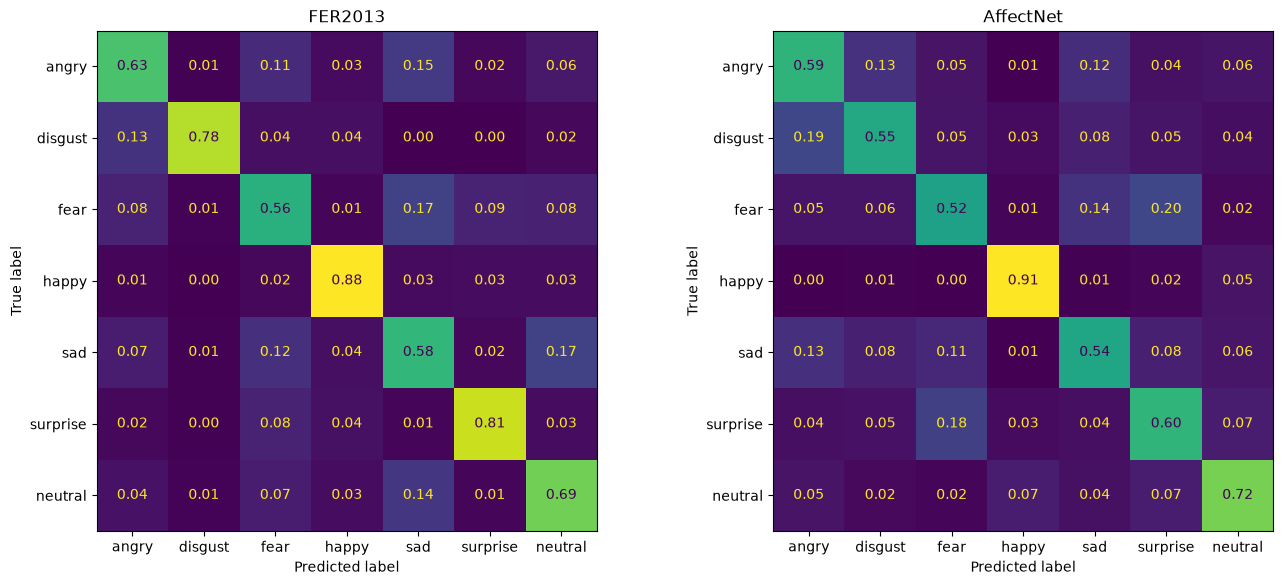

In [12]:
print('Confusion matrices of the best model on both test sets (each row sums to 1):', best_name)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (data, y) in zip(axes, [('FER2013', y_test), ('AffectNet', y_aff_test)]):
    ConfusionMatrixDisplay(confusion_matrix(y, test_pred[best_name, data], normalize='true'), display_labels=classes).plot(ax=ax, values_format='.2f', colorbar=False)
    ax.set_title(data)
plt.savefig('../../results/emotion/confusion_matrices.png', bbox_inches='tight')
plt.show()

In [13]:
print('Per-emotion results of the best model:', best_name)
for data, y in [('FER2013', y_test), ('AffectNet', y_aff_test)]:
    print(data)
    print(classification_report(y, test_pred[best_name, data], target_names=classes, digits=3))

Per-emotion results of the best model: ResNet-18 (FER2013 + AffectNet)
FER2013
              precision    recall  f1-score   support

       angry      0.691     0.627     0.657       491
     disgust      0.683     0.782     0.729        55
        fear      0.571     0.559     0.565       528
       happy      0.907     0.879     0.893       879
         sad      0.551     0.582     0.566       594
    surprise      0.771     0.810     0.790       416
     neutral      0.672     0.693     0.682       626

    accuracy                          0.707      3589
   macro avg      0.692     0.705     0.698      3589
weighted avg      0.709     0.707     0.707      3589

AffectNet
              precision    recall  f1-score   support

       angry      0.562     0.593     0.577       643
     disgust      0.530     0.551     0.540       494
        fear      0.534     0.521     0.528       633
       happy      0.878     0.909     0.893      1009
         sad      0.537     0.540     0.539

In [14]:
print('Exporting ResNet-18 (FER2013 + AffectNet) for the app as emotion.pt')
torch.save({'state_dict': {k[4:]: v.cpu() for k, v in combined.state_dict().items() if k.startswith('net.')},
            'classes': classes, 'face_size': 48, 'img_size': 96,
            'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}, 'emotion.pt')
print('Saved emotion.pt:', round(os.path.getsize('emotion.pt') / 1e6, 1), 'MB')

Exporting ResNet-18 (FER2013 + AffectNet) for the app as emotion.pt
Saved emotion.pt: 44.8 MB
